   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.3333

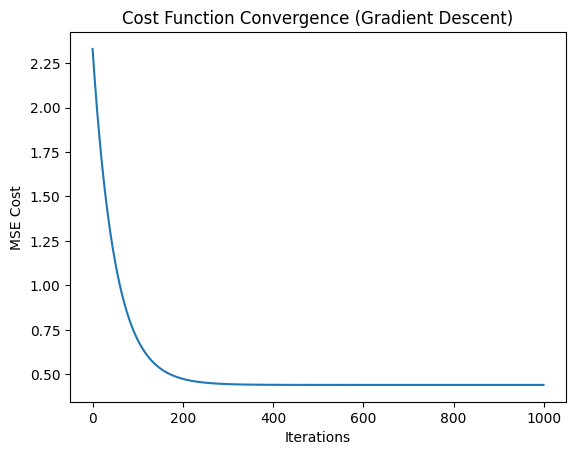

NE => theta0=1.9272, theta1=0.2567
Gradient Descent     MSE=0.8898 RMSE=0.9433 R2=0.0493
Normal Equation      MSE=0.8898 RMSE=0.9433 R2=0.0493


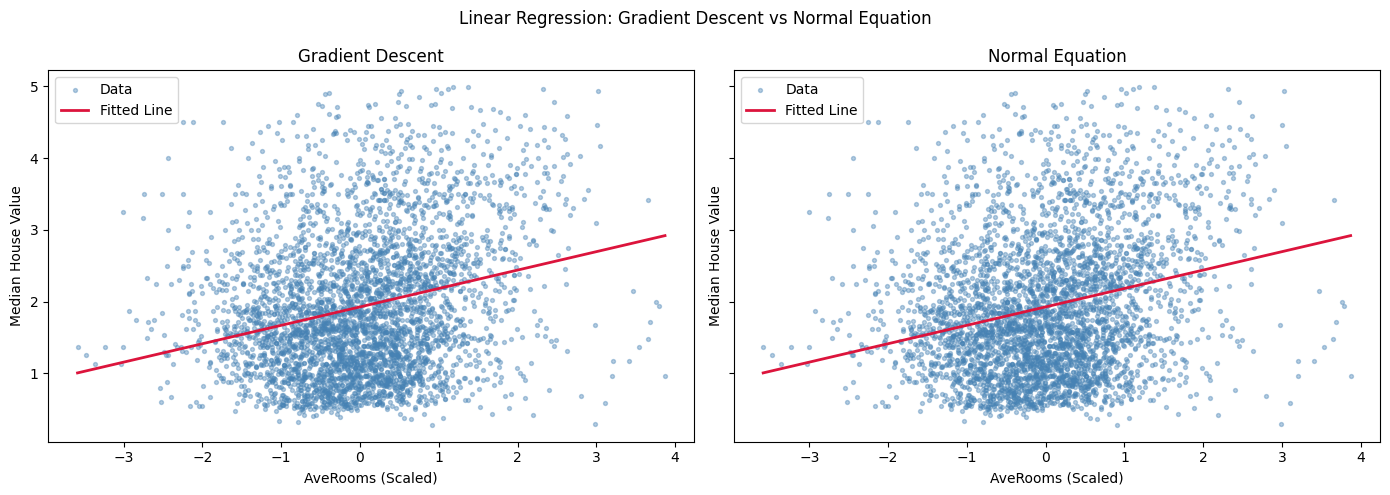

In [7]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# Load dataset
data = fetch_california_housing(as_frame=True)
df = data.frame
print(df.head())
print(df.describe())

# Select single feature
X = df[['AveRooms']].values
print(len(X))
y = df['MedHouseVal'].values

# Clip outliers (optional, for better visualization)
mask = (X.flatten() < 10) & (y < 5)
X, y = X[mask], y[mask]

# Train-test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Feature scaling
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# Gradient Descent
def gradient_descent(X, y, lr=0.01, epochs=1000):
    m = len(y)
    theta0, theta1 = 0.0, 0.0
    cost_history = []

    for _ in range(epochs):
        y_p = theta0 + theta1 * X.flatten()
        error = y_p - y

        theta0 -= lr * (1/m) * np.sum(error)
        theta1 -= lr * (1/m) * np.sum(error * X.flatten())

        cost_history.append((1/(2*m)) * np.sum(error**2))

    return theta0, theta1, cost_history

t0_gd, t1_gd, costs = gradient_descent(
    X_train_sc, y_train, lr=0.01, epochs=1000
)

print(f'GD => theta0={t0_gd:.4f}, theta1={t1_gd:.4f}')

# Plot cost convergence
plt.plot(costs)
plt.title('Cost Function Convergence (Gradient Descent)')
plt.xlabel('Iterations')
plt.ylabel('MSE Cost')
plt.show()

# Normal Equation
def normal_equation(X, y):
    X_b = np.c_[np.ones(len(X)), X]
    theta = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y
    return theta[0], theta[1]

t0_ne, t1_ne = normal_equation(X_train_sc, y_train)

print(f'NE => theta0={t0_ne:.4f}, theta1={t1_ne:.4f}')

# Evaluation
for name, t0, t1 in [
    ('Gradient Descent', t0_gd, t1_gd),
    ('Normal Equation', t0_ne, t1_ne)
]:
    y_pred = t0 + t1 * X_test_sc.flatten()

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f'{name:20s} MSE={mse:.4f} RMSE={mse**0.5:.4f} R2={r2:.4f}')

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, (name, t0, t1) in zip(axes, [
    ('Gradient Descent', t0_gd, t1_gd),
    ('Normal Equation', t0_ne, t1_ne)
]):
    ax.scatter(
        X_test_sc.flatten(), y_test,
        alpha=0.4, s=8, color='steelblue', label='Data'
    )

    xs = np.linspace(X_test_sc.min(), X_test_sc.max(), 200)
    ax.plot(
        xs, t0 + t1 * xs,
        color='crimson', lw=2, label='Fitted Line'
    )

    ax.set_title(name)
    ax.set_xlabel('AveRooms (Scaled)')
    ax.set_ylabel('Median House Value')
    ax.legend()

plt.suptitle('Linear Regression: Gradient Descent vs Normal Equation')
plt.tight_layout()
plt.show()
